# Day05 — error analysis

## D5-01 — проверенный validation reference

Цель: загрузить сохранённые predictions выбранного Day04 candidate без fit, CV или оценки test. Входы — Day02 processed/provenance, Day03 manifest/reference, Day04 selection/config/predictions/metrics/provenance.

SHA-256 проверяет байты artifacts, а semantic checks — IDs, порядок, labels и параметры. Join выполняется one-to-one по `source_row_id`: одинаковая длина таблиц не гарантирует соответствия предложений. Все validation строки сохраняются; `errors` — только фильтр, не новая выборка для настройки модели.

In [1]:
from pathlib import Path
import sys
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src/finnews_sentiment").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/finnews_sentiment").is_dir():
    raise RuntimeError("Run from the project root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))

from finnews_sentiment.models.error_analysis import load_validation_analysis

analysis = load_validation_analysis(ROOT)
print("Candidate:", analysis.candidate_id)
print("Selection:", analysis.selection_path.relative_to(ROOT))
print("Parameters:", analysis.parameters)

Candidate: linear_svc
Selection: reports/day04/selection.json
Parameters: {'tfidf': {'max_features': 5000, 'ngram_range': [1, 2], 'analyzer': 'word', 'lowercase': False, 'stop_words': None, 'min_df': 1, 'max_df': 1.0, 'use_idf': True, 'smooth_idf': True, 'sublinear_tf': False, 'norm': 'l2', 'token_pattern': '(?u)\\b\\w\\w+\\b', 'strip_accents': None}, 'classifier': {'C': 1.0, 'class_weight': None, 'dual': 'auto', 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 5000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': 42, 'tol': 0.0001, 'verbose': 0}}


In [2]:
n_valid = len(analysis.table)
n_errors = len(analysis.errors)
print("Table shape:", analysis.table.shape)
print(f"N_valid={n_valid}; errors={n_errors}; error rate={n_errors / n_valid:.2%}")
display(analysis.table.head())
display(analysis.errors.head())

Table shape: (553, 9)
N_valid=553; errors=84; error rate=15.19%


,source_row_id,group_id,text,text_clean,true_label_id,pred_label_id,true_label,pred_label,is_error
0,2,2,"For the last quarter of 2010 , Componenta 's n...","for the last quarter of 2010 , componenta 's n...",2,2,positive,positive,False
1,3,3,"In the third quarter of 2010 , net sales incre...","in the third quarter of 2010 , net sales incre...",2,2,positive,positive,False
2,11,11,Consolidated net sales increased 16 % to reach...,consolidated net sales increased 16 % to reach...,2,2,positive,positive,False
3,16,16,"Lifetree was founded in 2000 , and its revenue...","lifetree was founded in 2000 , and its revenue...",2,1,positive,neutral,True
4,28,28,The fair value of the property portfolio doubl...,the fair value of the property portfolio doubl...,2,1,positive,neutral,True


,source_row_id,group_id,text,text_clean,true_label_id,pred_label_id,true_label,pred_label,is_error
3,16,16,"Lifetree was founded in 2000 , and its revenue...","lifetree was founded in 2000 , and its revenue...",2,1,positive,neutral,True
4,28,28,The fair value of the property portfolio doubl...,the fair value of the property portfolio doubl...,2,1,positive,neutral,True
8,59,59,The combination of all services enabling us to...,the combination of all services enabling us to...,2,1,positive,neutral,True
10,72,72,Biohit already services many current Genesis c...,biohit already services many current genesis c...,2,1,positive,neutral,True
20,114,114,Finnish Okmetic that manufactures and processe...,finnish okmetic that manufactures and processe...,2,1,positive,neutral,True


### Интерпретация и самопроверка

Таблица `(N_valid, 9)` сохраняет raw/clean text и исходный manifest order. `pred_label_id` явно получен из `selected_pred_label_id`. Показаны первые реальные ошибки в исходном порядке; это проверка загрузки, ручной разбор остаётся D5-03. Доля ошибок равна `1 − accuracy`, но не заменяет macro F1: частый neutral может доминировать в accuracy. Нулевое число ошибок допустимо.

1. Почему одинаковой длины таблиц недостаточно для alignment?
2. Почему переставленные reference predictions вызывают ошибку, хотя join по ID технически возможен?
3. Какие проверки защищают от изменения данных и от пересечения text groups?
4. Почему найденные ошибки не дают права менять текущую модель перед test?

## D5-02 — confusion matrix и направления ошибок

Цель: превратить проверенные validation labels `(N_valid,)` в counts и row-normalized матрицы `(3, 3)`, шесть направленных пар и per-class metrics. Модель не вызывается: используются сохранённые predictions D5-01.

Строки = **true**, столбцы = **predicted**, фиксированный порядок `negative / neutral / positive`. Counts показывают число строк. Нормировка `M[i, j] / support[i]` показывает долю исходов **внутри истинного класса**; диагональ равна recall, а precision использует сумму столбца. При support=0 строка нулевая и подписана как absent.

Сумма counts = N_valid; диагональ = верные ответы; off-diagonal = ошибки. Все сохранённые строки, включая duplicate groups, учитываются по одному разу: они не становятся независимыми наблюдениями.

Validation: N=553; accuracy=0.848101; macro F1=0.805961
Counts: rows=true, columns=predicted


pred_label,negative,neutral,positive
true_label,,,
negative,47,15,5
neutral,3,326,15
positive,4,42,96


Normalized: count / true support


pred_label,negative,neutral,positive
true_label,,,
negative,0.701493,0.223881,0.074627
neutral,0.008721,0.947674,0.043605
positive,0.028169,0.295775,0.676056


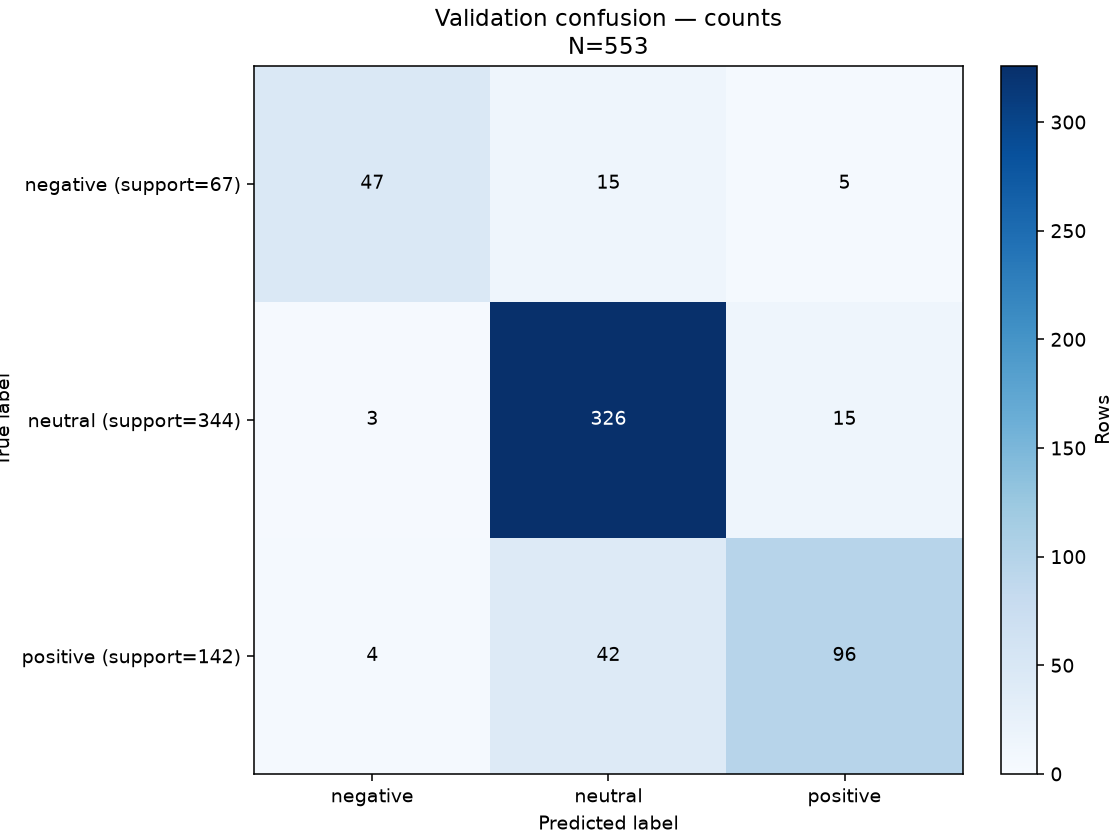

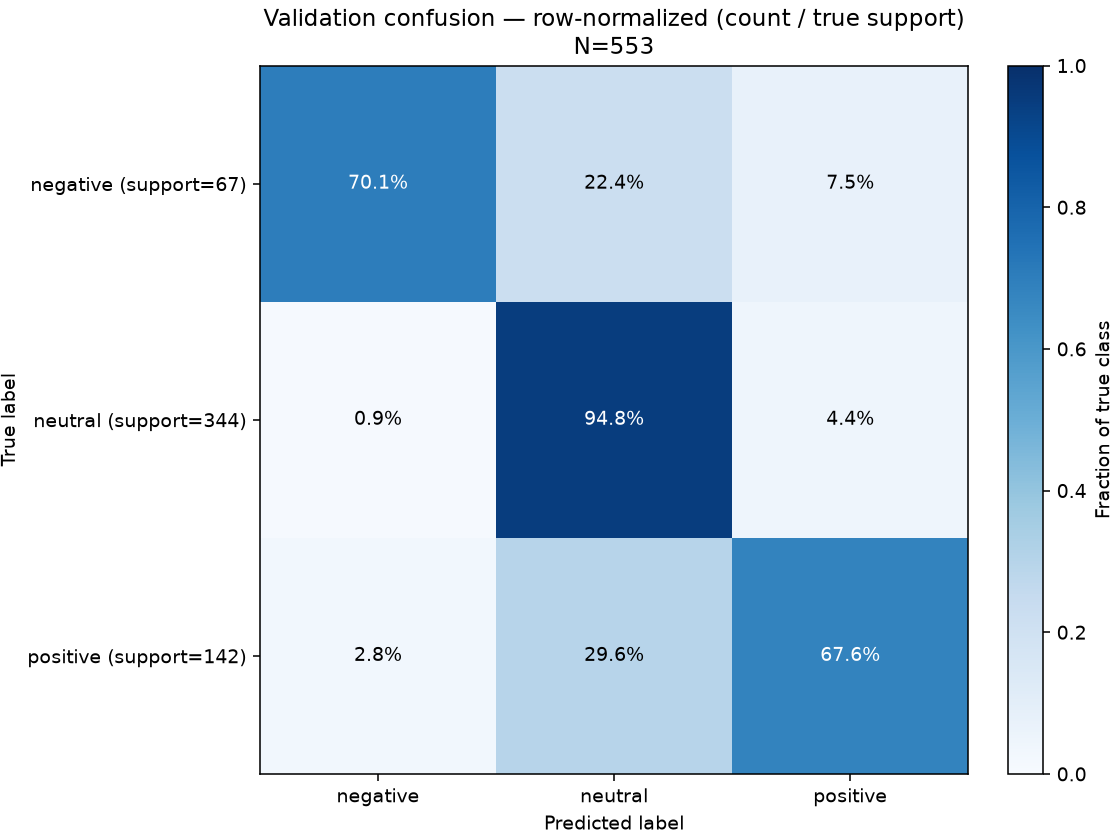

In [3]:
from finnews_sentiment.models.confusion import build_validation_confusion, save_validation_confusion
from IPython.display import Image

confusion = build_validation_confusion(analysis.table)
confusion_paths = save_validation_confusion(confusion, ROOT / "reports/day05")
print(f"Validation: N={confusion.metrics.n_samples}; accuracy={confusion.metrics.accuracy:.6f}; macro F1={confusion.metrics.macro_f1:.6f}")
print("Counts: rows=true, columns=predicted")
display(confusion.counts)
print("Normalized: count / true support")
display(confusion.normalized)
display(Image(filename=str(confusion_paths["counts_png"])))
display(Image(filename=str(confusion_paths["normalized_png"])))

In [4]:
print("Per-class metrics: zero_division=0; labels=[0, 1, 2]")
display(confusion.per_class)
print("Six directed error pairs; fraction_of_true = count / true_support")
display(confusion.pairs)
print("Saved Day05 artifacts:")
for artifact_name, artifact_path in confusion_paths.items():
    print(artifact_name, artifact_path.relative_to(ROOT))

Per-class metrics: zero_division=0; labels=[0, 1, 2]


,class_id,class_name,precision,recall,f1,support,predicted_count
0,0,negative,0.870370,0.701493,0.776860,67,54
1,1,neutral,0.851175,0.947674,0.896836,344,383
2,2,positive,0.827586,0.676056,0.744186,142,116


Six directed error pairs; fraction_of_true = count / true_support


,true_label,pred_label,count,true_support,fraction_of_true
0,negative,neutral,15,67,0.223881
1,negative,positive,5,67,0.074627
2,neutral,negative,3,344,0.008721
3,neutral,positive,15,344,0.043605
4,positive,negative,4,142,0.028169
5,positive,neutral,42,142,0.295775


Saved Day05 artifacts:
counts_csv reports/day05/validation_confusion_counts.csv
counts_png reports/day05/validation_confusion_counts.png
normalized_csv reports/day05/validation_confusion_normalized.csv
normalized_png reports/day05/validation_confusion_normalized.png
pairs_csv reports/day05/confusion_pairs.csv


### Интерпретация и самопроверка

В validation 553 строки: 469 верных ответов и 84 ошибки. Самое частое направление — **positive → neutral: 42/142 = 29,58%** истинных positive. Обратное направление neutral → positive: **15/344 = 4,36%**. Сравнение counts без этих denominators скрыло бы различие долей.

Negative → neutral: **15/67 = 22,39%**; обратное neutral → negative: **3/344 = 0,87%**. Negative → positive: 5/67 = 7,46%; positive → negative: 4/142 = 2,82%. Среди всех шести пар positive → neutral наиболее частая и по count, и по доле истинного класса.

Recall: negative **70,15%**, neutral **94,77%**, positive **67,61%**. Accuracy **84,81%** при macro F1 **0,805961**: neutral содержит 344/553 строк, а macro F1 даёт каждому из трёх классов одинаковый вес. Все классы присутствуют; нулевых support здесь нет. Это описательные validation результаты; они не объясняют причины ошибок и не используются для изменения параметров. Ручной разбор предложений остаётся D5-03.

1. Чем true negative → predicted neutral отличается от обратной пары? Какие у них denominators?
2. Почему большой count ошибок neutral сам по себе не означает худший recall?
3. Почему диагональ нормированной по строкам матрицы равна recall, а не precision?
4. Что означает нулевая строка при support=0, и почему это не идеальное качество?
5. Почему counts duplicate rows не равны числу независимых наблюдений?

## D5-03 — реальные validation examples и ручной разбор

**Цель:** из 84 validation ошибок выбрать до трёх строк на каждую true→pred пару по возрастанию `source_row_id`, затем присоединить проверенные ручные annotations. Вход — aligned table D5-01 и tracked `docs/day05_failure_cases.csv`; выход — не более 18 examples с raw/clean text, labels, IDs, group counts и разбором.

Выборка детерминированная, не случайная: доли категорий описывают только просмотренные examples. `observation` — что видно в тексте; `hypothesis` — возможное объяснение (может быть пустым); `rationale` — основание primary category. Это не новая ground truth и не доказательство причины решения модели. Пустые пары явно отмечаются, строки не придумываются. Duplicate groups сохраняются и подсчитываются.

In [5]:
import pandas as pd
from finnews_sentiment.models.failure_cases import select_validation_examples, load_failure_annotations

example_selection = select_validation_examples(analysis.table)
reviewed_examples = load_failure_annotations(
    ROOT / "docs/day05_failure_cases.csv", example_selection.examples,
)
print("Pair selection: first three source_row_id per directed pair")
display(example_selection.pairs)
print(f"Reviewed: {len(reviewed_examples)} rows / {reviewed_examples['group_id'].nunique()} unique groups")
print(f"All validation: {len(analysis.table)} rows / {analysis.table['group_id'].nunique()} groups")
print(f"All errors: {len(analysis.errors)} rows / {analysis.errors['group_id'].nunique()} groups")
print("Selected rows from groups repeated anywhere in validation:", int(reviewed_examples["is_duplicate_group"].sum()))
display(reviewed_examples[[
    "source_row_id", "group_id", "true_label", "pred_label",
    "group_validation_rows", "group_error_rows", "group_selected_rows", "is_duplicate_group",
]])

Pair selection: first three source_row_id per directed pair


,true_label,pred_label,available_errors,selected_examples,selected_groups,status
0,negative,neutral,15,3,3,selected
1,negative,positive,5,3,3,selected
2,neutral,negative,3,3,3,selected
3,neutral,positive,15,3,3,selected
4,positive,negative,4,3,3,selected
5,positive,neutral,42,3,3,selected


Reviewed: 18 rows / 18 unique groups
All validation: 553 rows / 552 groups
All errors: 84 rows / 84 groups
Selected rows from groups repeated anywhere in validation: 0


,source_row_id,group_id,true_label,pred_label,group_validation_rows,group_error_rows,group_selected_rows,is_duplicate_group
0,534,534,negative,neutral,1,1,1,False
1,2866,2866,negative,neutral,1,1,1,False
2,2982,2982,negative,neutral,1,1,1,False
3,518,518,negative,positive,1,1,1,False
4,2854,2854,negative,positive,1,1,1,False
5,2855,2855,negative,positive,1,1,1,False
6,1428,1428,neutral,negative,1,1,1,False
7,2156,2156,neutral,negative,1,1,1,False
8,2598,2598,neutral,negative,1,1,1,False
9,743,743,neutral,positive,1,1,1,False


In [6]:
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    for pair in example_selection.pairs.to_dict("records"):
        pair_examples = reviewed_examples.loc[
            reviewed_examples["true_label"].eq(pair["true_label"])
            & reviewed_examples["pred_label"].eq(pair["pred_label"])
        ]
        print(f"{pair['true_label']} → {pair['pred_label']}: {pair['status']}; selected={len(pair_examples)}")
        if pair_examples.empty:
            print("No examples: this directed error pair is empty.")
        else:
            display(pair_examples[["source_row_id", "group_id", "true_label", "pred_label", "text", "text_clean"]])
            display(pair_examples[["source_row_id", "primary_category", "observation", "hypothesis", "rationale"]])

negative → neutral: selected; selected=3


,source_row_id,group_id,true_label,pred_label,text,text_clean
0,534,534,negative,neutral,"`` However , the rapidly increasing costs and the strengthening of the euro were challenging for the whole industry , and they impacted on our results . ''","`` however , the rapidly increasing costs and the strengthening of the euro were challenging for the whole industry , and they impacted on our results . ''"
1,2866,2866,negative,neutral,Nokia Siemens Networks has struggled to make a profit in the past two years .,nokia siemens networks has struggled to make a profit in the past two years .
2,2982,2982,negative,neutral,Chief executive officer Olli-Pekka Kallasvuo 's changes on Tuesday mark the third time in nine months the company has reshuffled executives and operations as Nokia loses ground to Apple 's iPhone and RIM 's BlackBerry .,chief executive officer olli-pekka kallasvuo 's changes on tuesday mark the third time in nine months the company has reshuffled executives and operations as nokia loses ground to apple 's iphone and rim 's blackberry .


,source_row_id,primary_category,observation,hypothesis,rationale
0,534,financial context,Описаны быстро растущие издержки и укрепление евро; они названы трудностями для отрасли и повлияли на результаты.,"Возможно, локальные признаки costs/results не передают направленность воздействия на компанию.","Negative → neutral: в тексте есть негативная оценка условий; финансовый контекст наблюдаем, причинность ошибки не установлена."
1,2866,financial context,Компания struggled to make a profit на протяжении двух лет.,"Возможно, сочетание struggled to make меняет смысл слова profit недостаточно для текущего представления.","Negative → neutral: трудности с получением прибыли выражены фразой, а не только отдельным финансовым термином."
2,2982,financial context,"Перестановки руководства описаны вместе с тем, что Nokia loses ground конкурентам.","Возможно, длинный контекст кадровых изменений ослабляет влияние фразы loses ground.",Negative → neutral: негативный сигнал связан с конкурентной позицией в конце длинного предложения.


negative → positive: selected; selected=3


,source_row_id,group_id,true_label,pred_label,text,text_clean
3,518,518,negative,positive,Cash Flow from Operations for the most recent quarter also reached a eight year low .,cash flow from operations for the most recent quarter also reached a eight year low .
4,2854,2854,negative,positive,Earnings per share ( EPS ) amounted to a loss of EUR0 .05 .,earnings per share ( eps ) amounted to a loss of eur0 .05 .
5,2855,2855,negative,positive,Earnings per share ( EPS ) amounted to a loss of to EUR0 .06 .,earnings per share ( eps ) amounted to a loss of to eur0 .06 .


...

,source_row_id,group_id,true_label,pred_label,text,text_clean
12,321,321,positive,negative,The growth of net sales in the first half of 2008 has been 28 % compared with the first half of 2007 .,the growth of net sales in the first half of 2008 has been 28 % compared with the first half of 2007 .
13,1294,1294,positive,negative,"in Q1 '10 19 April 2010 - Finnish forest machinery and equipment maker Ponsse Oyj HEL : PON1V said today that it expects to swing to a net profit of some EUR6 .3 m in the first quarter of 2010 , from an EUR9 .6 m loss a year earlier .","in q1 '10 19 april 2010 - finnish forest machinery and equipment maker ponsse oyj hel : pon1v said today that it expects to swing to a net profit of some eur6 .3 m in the first quarter of 2010 , from an eur9 .6 m loss a year earlier ."
14,1374,1374,positive,negative,"In the first quarter of 2010 , the mark-to-market result was a pretax profit of EUR 133 million versus a loss of EUR 32 million in the same period last year .","in the first quarter of 2010 , the mark-to-market result was a pretax profit of eur 133 million versus a loss of eur 32 million in the same period last year ."


,source_row_id,primary_category,observation,hypothesis,rationale
12,321,other/unclear,Указан рост net sales на 28% к первому полугодию предыдущего года.,,Positive → negative при явно названном росте; по одному предложению причина ошибки не установлена.
13,1294,negation/comparison,Ожидается переход от убытка EUR9 .6 m годом ранее к прибыли EUR6 .3 m в первом квартале 2010 года.,"Возможно, историческое loss влияет на предсказание без достаточного учёта перехода к прибыли.","Positive → negative: прибыль относится к текущему прогнозу, а убыток к прошлому периоду; это временное сравнение."
14,1374,negation/comparison,В первом квартале 2010 прибыль EUR133 million сопоставлена с убытком EUR32 million годом ранее.,"Возможно, versus и временная привязка не обеспечивают различение текущей прибыли и прошлого убытка.",Positive → negative: наличие profit и loss в одной строке не делает текущий результат смешанным; важны периоды.


positive → neutral: selected; selected=3


,source_row_id,group_id,true_label,pred_label,text,text_clean
15,16,16,positive,neutral,"Lifetree was founded in 2000 , and its revenues have risen on an average by 40 % with margins in late 30s .","lifetree was founded in 2000 , and its revenues have risen on an average by 40 % with margins in late 30s ."
16,28,28,positive,neutral,"The fair value of the property portfolio doubled as a result of the Kapiteeli acquisition and totalled EUR 2,686.2 1,259.7 million .","the fair value of the property portfolio doubled as a result of the kapiteeli acquisition and totalled eur 2,686.2 1,259.7 million ."
17,59,59,positive,neutral,"The combination of all services enabling us to offer a complex and strengthened service chain not only limited to the Baltic port connections but also for getting access to the world wide Grimaldi Network into the Mediterranean , Africa and North America `` says Uwe Bakosch .","the combination of all services enabling us to offer a complex and strengthened service chain not only limited to the baltic port connections but also for getting access to the world wide grimaldi network into the mediterranean , africa and north america `` says uwe bakosch ."


,source_row_id,primary_category,observation,hypothesis,rationale
15,16,financial context,"Доходы росли в среднем на 40%, указаны margins in late 30s; рядом приведён год основания.","Возможно, описательный контекст компании ослабляет сигнал роста доходов.","Positive → neutral: рост revenues явно присутствует, но причина нейтрального предсказания не установлена."
16,28,financial context,Справедливая стоимость портфеля удвоилась вследствие приобретения Kapiteeli; далее стоят несколько числовых величин.,"Возможно, смысл doubled и контекст приобретения представлены недостаточно на фоне числового описания.",Positive → neutral: наблюдаемый рост стоимости не требует исправления исходного label или чисел.
17,59,financial context,Описано расширение сервисной цепочки и доступа к сети Grimaldi за пределами Балтики.,"Возможно, положительный смысл расширения возможностей не выражен сильным локальным признаком.","Positive → neutral: потенциальная польза раскрыта через длинное описание услуг, а не краткий финансовый итог."


In [7]:
category_counts = reviewed_examples["primary_category"].value_counts().rename("count").to_frame()
category_counts["reviewed_rows"] = len(reviewed_examples)
category_counts["fraction_of_reviewed"] = category_counts["count"] / len(reviewed_examples) if len(reviewed_examples) else 0.0
print("Category denominator = reviewed examples only")
display(category_counts)

report_dir = ROOT / "reports/day05"
report_dir.mkdir(parents=True, exist_ok=True)
analysis.table.to_csv(report_dir / "validation_analysis.csv", index=False)
analysis.errors.to_csv(report_dir / "validation_errors.csv", index=False)
reviewed_examples.to_csv(report_dir / "validation_examples.csv", index=False)
print("Saved all validation rows, all errors, and annotated examples separately.")

Category denominator = reviewed examples only


,count,reviewed_rows,fraction_of_reviewed
primary_category,,,
financial context,12,18,0.666667
negation/comparison,3,18,0.166667
insufficient context/ambiguous label,2,18,0.111111
other/unclear,1,18,0.055556


Saved all validation rows, all errors, and annotated examples separately.


### Наблюдения, ограничения и будущие проверки

1. **Financial context:** EPS `loss` в ID 2854/2855 (negative→positive), снижение `ownership` в ID 2598 (neutral→negative) и запуск продукта ID 1593 (neutral→positive) показывают разные типы событий. Отдельное слово не определяет финансовую оценку без объекта и контекста; веса признаков здесь не исследовались.
2. **Сравнение и отрицание:** ID 1294/1374 (positive→negative) сопоставляют текущую/ожидаемую прибыль с прошлым убытком. ID 2156 (neutral→negative) отрицает изменение плана. Это наблюдения в тексте, а не доказательство того, что historical loss или отрицание вызвали ошибку.
3. **Достигнутый результат и контекст:** ID 743 (neutral→positive) говорит о необходимости улучшения, ID 1428 (neutral→negative) — об абсолютной прибыли без сравнения. Labels не исправляются по несогласию модели.
4. **Явные positive сигналы тоже пропускаются:** ID 16/28 (positive→neutral) сообщают о росте и удвоении, ID 59 — о расширении возможностей. Для ID 321 (positive→negative) рост продаж виден прямо, но причина ошибки остаётся `other/unclear`.

Просмотрено **18 строк / 18 groups**, все выбранные groups встречаются в validation один раз. ID 2854 и 2855 похожи, но не exact duplicates. Разные IDs сами по себе не доказывают независимость. Среди просмотренных: financial context 12/18; negation/comparison 3/18; insufficient context/ambiguous label 2/18; other/unclear 1/18. Эти доли нельзя переносить на 84 ошибки или 553 validation строки. Категории mixed sentiment и preprocessing/representation limitation не навязывались: в выбранных raw/clean texts видно lowercasing, но нет наблюдаемого удаления отрицания или числового сигнала.

**Будущие гипотезы:** приоритет 1 — заранее задать contextual features сравнений/временной привязки и проверить ablation на общих train-only group-aware folds; приоритет 2 — аналогично проверить признаки типа финансового события и отличия необходимости от достигнутого результата. Learned transformations fit внутри Pipeline каждого fold, сравнение по macro F1 и per-class recall. Validation уже просмотрена, поэтому её нельзя считать независимым новым подтверждением. Эти эксперименты здесь не выполняются; текущая модель не меняется перед test. Подробности и ограничения — `docs/day05.md`.

### Самопроверка

1. Доказывает ли один пример с `wo n't`, что модель не понимает отрицания?
2. Почему 12/18 financial context не означает, что эта категория объясняет 66,67% всех ошибок?
3. Чем observation про прошлый loss отличается от гипотезы о его влиянии на prediction?
4. Зачем проверять group counts, если source IDs уникальны?
5. Почему разбор validation не даёт права настроить модель и затем назвать прежний validation независимой проверкой?

## D5-04 — frozen protocol, validation replay и final held-out test

**Цель:** однократно оценить прежний выбранный candidate на сохранённом test, не используя результаты для настройки. Первый запуск выполняется **отдельной явной CLI-командой** после offline gates:

```bash
PYTHONPATH=src venv/bin/python -m finnews_sentiment.models.final_evaluation
```

Порядок первого запуска: проверить provenance/checksums/config/runtime → записать `frozen_protocol.json` → fit выбранного Pipeline **только на Day03 train** → exact replay всех validation predictions Day04 → один test `predict` → metrics и confusion matrices → проверка roundtrips/hashes → последним записать `final_evaluation.json`.

Train+validation не объединяются: иначе мы оценивали бы другое обученное решение. TF-IDF vocabulary/IDF fit внутри Pipeline; sparse train shape `(N_train, V)`, test predictions `(N_test,)`. Replay сверяет IDs, true labels, порядок и selected predictions; несовпадение или `ConvergenceWarning` останавливают процесс до test predict. Это проверка воспроизводимости, а не повторный выбор модели.

**Notebook читает только завершённый cache** через `load_final_evaluation`: проверяет текущие inputs/config/runtime и protocol/output hashes, IDs/order/labels и пересчитывает metrics/matrices из cached predictions, без fit/predict. Отсутствующий или повреждённый cache не запускает оценку автоматически. При partial artifacts требуется явная диагностика; файлы не удаляются и не перезаписываются. Маркер завершения не делает запись нескольких файлов общей транзакцией: exactly-once prediction при аварии до сохранения cache гарантировать нельзя.

In [8]:
from finnews_sentiment.models.final_evaluation import load_final_evaluation

final_result = load_final_evaluation(ROOT)
print("Final cache status:", final_result.cache_status)
print("Frozen protocol:", (final_result.directory / "frozen_protocol.json").relative_to(ROOT))
print("Candidate:", final_result.candidate_id)
print("Fit policy:", final_result.protocol["fit_policy"])
print("Runtime versions:", final_result.protocol["runtime_versions"])
print("Validation replay: exact_match (verified completion record and current reference)")
print(f"TF-IDF train shape: ({final_result.n_train}, {final_result.n_features})")
print("Test predictions shape:", final_result.predictions["pred_label_id"].shape)
print(f"evaluation_split=test; N_test={len(final_result.predictions)}")
print(f"Accuracy={final_result.confusion.metrics.accuracy:.6f}; macro F1={final_result.confusion.metrics.macro_f1:.6f}")
display(final_result.confusion.per_class)

Final cache status: reused
Frozen protocol: reports/day05/frozen_protocol.json
Candidate: linear_svc
Fit policy: day03_train_only
Runtime versions: {'python': '3.14.6', 'pandas': '3.0.6', 'numpy': '2.5.3', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'joblib': '1.6.0', 'threadpoolctl': '3.7.0'}
Validation replay: exact_match (verified completion record and current reference)
TF-IDF train shape: (2210, 5000)
Test predictions shape: (690,)
evaluation_split=test; N_test=690
Accuracy=0.856522; macro F1=0.797050


,class_id,class_name,precision,recall,f1,support,predicted_count
0,0,negative,0.941176,0.571429,0.711111,84,51
1,1,neutral,0.858921,0.967290,0.909890,428,482
2,2,positive,0.821656,0.724719,0.770149,178,157


Final test confusion: rows=true, columns=predicted; negative/neutral/positive


pred_label,negative,neutral,positive
true_label,,,
negative,48,21,15
neutral,1,414,13
positive,2,47,129


pred_label,negative,neutral,positive
true_label,,,
negative,0.571429,0.250000,0.178571
neutral,0.002336,0.967290,0.030374
positive,0.011236,0.264045,0.724719


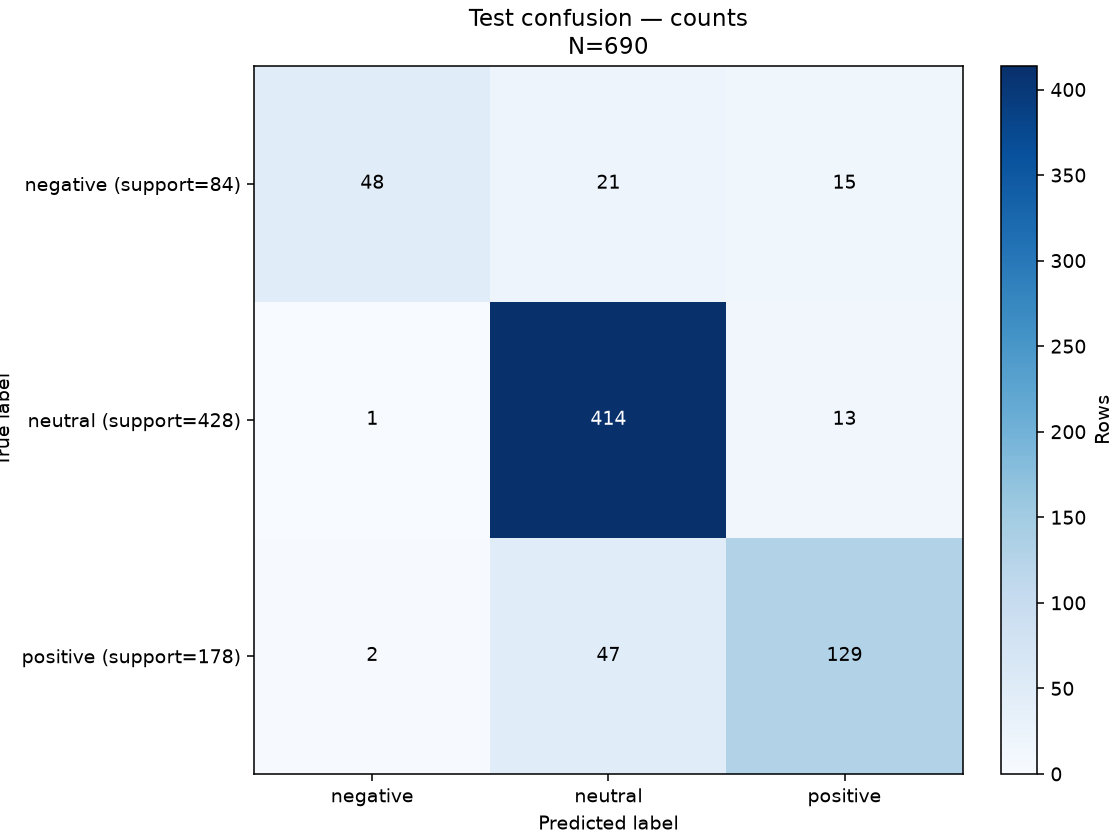

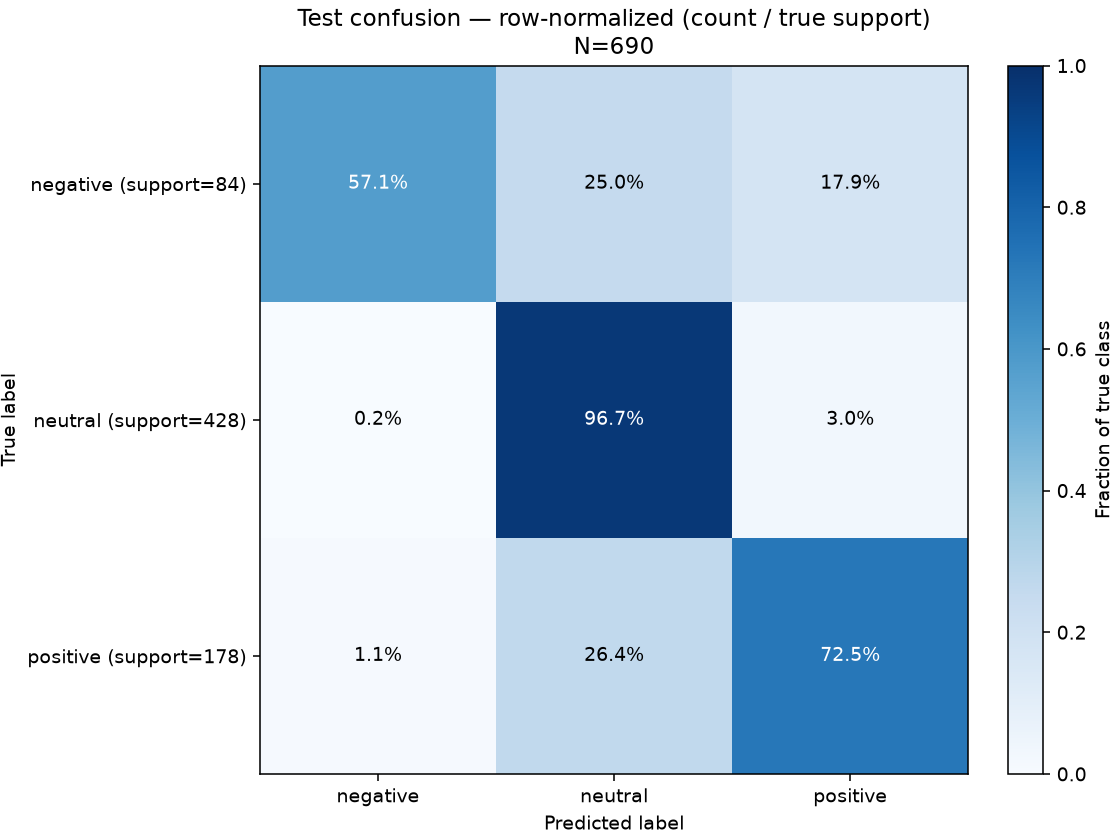

In [9]:
print("Final test confusion: rows=true, columns=predicted; negative/neutral/positive")
display(final_result.confusion.counts)
display(final_result.confusion.normalized)
display(Image(filename=str(final_result.directory / "test_confusion_counts.png")))
display(Image(filename=str(final_result.directory / "test_confusion_normalized.png")))

### Интерпретация final test и самопроверка

Первый реальный CLI run: **created**, validation replay **exact_match** на 553 строках, train TF-IDF **(2210, 5000)**. Повторы и этот notebook читают **reused** cache без fit/predict.

На test **690 строк**, accuracy **0,856522**, macro F1 **0,797050**. Recall negative/neutral/positive: **57,14% / 96,73% / 72,47%**, support **84 / 428 / 178**. Это описательная held-out оценка замороженного решения. Per-class metrics показывают качество для каждого класса, macro F1 придаёт им одинаковый вес, accuracy учитывает частоты классов. Test и validation состоят из разных строк: их нельзя сравнивать как paired эксперимент. По итогам test модель, пороги, seed, preprocessing и правила выбора не меняются; новые test examples здесь не разбираются.

1. Почему fit на train+validation оценивал бы другое решение?
2. Почему replay mismatch должен остановить процесс до test predict?
3. Почему tuning после чтения test разрушает независимость оценки?
4. Что проверяет cache reuse и почему он не вызывает fit/predict?
5. Почему маркер, записанный последним, не гарантирует exactly-once prediction при аварии?

## D5-05 — воспроизводимый offline report

**Цель:** собрать report из проверенных Day02–Day04 reference, ручных annotations и final cache D5-04. Входы модели не изменяются, fit/predict/download/CV отсутствуют. Отчёт заново формирует validation tables, errors, annotated examples, confusion CSV/PNG, summary, observations и provenance. Test predictions/metrics/matrices остаются неизменными cache inputs.

`provenance.json` связывает отчёт с hashes inputs, manual annotations, frozen protocol, final cache marker и outputs; собственного checksum у него нет. `analysis_summary.json` фиксирует policies, class order, counts, denominators, groups и metrics отдельно для validation и test. Roundtrips и input immutability проверяются до записи. Нет timestamp: при одинаковых inputs и runtime report повторяется byte-for-byte. Запись нескольких файлов последовательная, не общая транзакция.

Report-only CLI:

```bash
PYTHONPATH=src venv/bin/python -m finnews_sentiment.models.run_error_analysis_day05
```

Отсутствующий/повреждённый final cache — явная ошибка; runner не запускает D5-04. Первый final run выполняется отдельно командой `finnews_sentiment.models.final_evaluation` из предыдущего раздела. Модельный bundle и inference относятся к Day06.

In [10]:
from finnews_sentiment.models.run_error_analysis_day05 import run_error_analysis_day05

day05_report = run_error_analysis_day05(ROOT)
print("Candidate:", day05_report.analysis.candidate_id)
print("Test cache:", day05_report.final.cache_status)
print("Validation rows/errors:", len(day05_report.analysis.table), len(day05_report.analysis.errors))
print("Reviewed rows/groups:", len(day05_report.reviewed_examples), day05_report.reviewed_examples["group_id"].nunique())
print("Summary policies:", day05_report.summary["metric_policy"])
display(day05_report.summary["validation"])
display(day05_report.summary["manual_review"])
display(day05_report.summary["test"])

Candidate: linear_svc
Test cache: reused
Validation rows/errors: 553 84
Reviewed rows/groups: 18 18
Summary policies: {'labels': [0, 1, 2], 'average': 'macro', 'zero_division': 0}


{'evaluation_split': 'validation',
 'n_samples': 553,
 'accuracy': 0.8481012658227848,
 'macro_f1': 0.8059606214204886,
 'per_class': [{'class_id': 0,
   'class_name': 'negative',
   'precision': 0.8703703703703703,
   'recall': 0.7014925373134329,
   'f1': 0.7768595041322314,
   'support': 67},
  {'class_id': 1,
   'class_name': 'neutral',
   'precision': 0.8511749347258486,
   'recall': 0.9476744186046512,
   'f1': 0.8968363136176066,
   'support': 344},
  {'class_id': 2,
   'class_name': 'positive',
   'precision': 0.8275862068965517,
   'recall': 0.676056338028169,
   'f1': 0.7441860465116279,
   'support': 142}],
 'n_errors': 84,
 'n_correct': 469,
 'error_fraction_of_validation': 0.1518987341772152,
 'n_groups': 552,
 'n_error_groups': 84,
 'retained_duplicate_rows': 1,
 'counts': [[47, 15, 5], [3, 326, 15], [4, 42, 96]],
 'normalized_by_true_support': [[0.7014925373134329,
   0.22388059701492538,
   0.07462686567164178],
  [0.00872093023255814, 0.9476744186046512, 0.043604651162

{'selection_policy': 'first three source_row_id per directed pair; fixed class order',
 'n_reviewed_rows': 18,
 'n_reviewed_groups': 18,
 'repeated_group_rows_in_examples': 0,
 'selected_rows_from_duplicate_validation_groups': 0,
 'source_row_ids': [534,
  2866,
  2982,
  518,
  2854,
  2855,
  1428,
  2156,
  2598,
  743,
  1582,
  1593,
  321,
  1294,
  1374,
  16,
  28,
  59],
 'pair_selection': [{'true_label': 'negative',
   'pred_label': 'neutral',
   'available_errors': 15,
   'selected_examples': 3,
   'selected_groups': 3,
   'status': 'selected'},
  {'true_label': 'negative',
   'pred_label': 'positive',
   'available_errors': 5,
   'selected_examples': 3,
   'selected_groups': 3,
   'status': 'selected'},
  {'true_label': 'neutral',
   'pred_label': 'negative',
   'available_errors': 3,
   'selected_examples': 3,
   'selected_groups': 3,
   'status': 'selected'},
  {'true_label': 'neutral',
   'pred_label': 'positive',
   'available_errors': 15,
   'selected_examples': 3,
   

{'evaluation_split': 'test',
 'cache_status': 'reused',
 'n_samples': 690,
 'accuracy': 0.8565217391304348,
 'macro_f1': 0.797050158244188,
 'per_class': [{'class_id': 0,
   'class_name': 'negative',
   'precision': 0.9411764705882353,
   'recall': 0.5714285714285714,
   'f1': 0.7111111111111111,
   'support': 84},
  {'class_id': 1,
   'class_name': 'neutral',
   'precision': 0.8589211618257261,
   'recall': 0.9672897196261683,
   'f1': 0.9098901098901099,
   'support': 428},
  {'class_id': 2,
   'class_name': 'positive',
   'precision': 0.821656050955414,
   'recall': 0.7247191011235955,
   'f1': 0.7701492537313432,
   'support': 178}],
 'counts': [[48, 21, 15], [1, 414, 13], [2, 47, 129]],
 'normalized_by_true_support': [[0.5714285714285714,
   0.25,
   0.17857142857142858],
  [0.002336448598130841, 0.9672897196261683, 0.030373831775700934],
  [0.011235955056179775, 0.2640449438202247, 0.7247191011235955]],
 'n_train': 2210,
 'n_features': 5000}

In [11]:
print("Report outputs (final cache is input):")
for name, path in day05_report.artifacts.items():
    print(name, path.relative_to(ROOT))
print("Input hashes:", len(day05_report.provenance["input_checksums"]))
print("Output hashes (excluding provenance itself):", len(day05_report.provenance["output_checksums"]))
print("Frozen protocol SHA-256:", day05_report.provenance["frozen_protocol_sha256"])
print("Final cache marker SHA-256:", day05_report.provenance["final_evaluation_sha256"])
print("Observations: reports/day05/observations.md; tracked conclusions: docs/day05.md")

Report outputs (final cache is input):
validation_analysis.csv reports/day05/validation_analysis.csv
validation_errors.csv reports/day05/validation_errors.csv
validation_examples.csv reports/day05/validation_examples.csv
confusion_pairs.csv reports/day05/confusion_pairs.csv
analysis_summary.json reports/day05/analysis_summary.json
observations.md reports/day05/observations.md
validation_confusion_counts.csv reports/day05/validation_confusion_counts.csv
validation_confusion_counts.png reports/day05/validation_confusion_counts.png
validation_confusion_normalized.csv reports/day05/validation_confusion_normalized.csv
validation_confusion_normalized.png reports/day05/validation_confusion_normalized.png
provenance.json reports/day05/provenance.json
Input hashes: 29
Output hashes (excluding provenance itself): 10
Frozen protocol SHA-256: 4a9a778085b8f082a20374bf46e1a2053a72aa9a6ee872e3e252dbb8a2570a37
Final cache marker SHA-256: 1cc8749072afec98f30c8107a92bb7c8d8a526bdc2063e8e7647df68f85e792b

### Интерпретация и самопроверка

Отчёт сохраняет границы исходных шагов: validation errors и ручной review остаются validation, final test — описательной оценкой замороженного решения. Доли категорий имеют denominator = reviewed examples, не все ошибки. Counts duplicate rows не означают независимые наблюдения. Один split и малый holdout ограничивают выводы; std CV не является доверительным интервалом, live financial quality не проверена.

1. Какие artifacts связывают метрику с конкретными данными, candidate и запуском?
2. Почему hashes final cache входят в report inputs, а не в перезаписываемые outputs?
3. Почему provenance не содержит свой checksum?
4. Что произойдёт при отсутствии test cache — и почему report не должен обучать модель?
5. Что означает byte-identical repeat и чего он не доказывает о качестве модели?